# Task 24 — 311 service-request routing: the right agency first time, and tomorrow's workload

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [311 Service Requests from 2020 to Present](https://data.cityofnewyork.us/Social-Services/311-Service-Requests-from-2020-to-Present/erm2-nwe9) (NYC Open Data, Socrata `erm2-nwe9`, read through its public API); the [Kaggle snapshot](https://www.kaggle.com/datasets/new-york-city/ny-311-service-requests) holds 2010–2019
**Task family:** routing over a governed taxonomy, taxonomy drift, risk scoring, count forecasting · **Companion task:** `03_complaint_triage_text.ipynb` (routing across a taxonomy change); `02_card_fraud_tabular.ipynb` for forward-in-time evaluation and drift

---

## The task card

> **Board question.** *NYC 311 took about 10,000 service requests a day in 2025, and at least one in 36 closed with "not our jurisdiction" or "referred to another agency". Once a request has its complaint type, can routing send at least 99.5 % to the agency that handles it, and keep that level when agencies rewrite the catalogue? How many bounces can a routing desk with 300 checks a day catch first? And can we tell each agency tomorrow's workload better than "same day last week" (10 % error city-wide)?*

**Business context.** 311 is New York City's front door for non-emergency services: the citizen or a call-taker picks a **complaint type** (and a descriptor inside it) from a catalogue the agencies own, and the request goes to that type's agency. The legacy estate: a customer-service platform, one work-order system per agency, the catalogue between them. Session 01 patterns: **online prediction** with a **human in the loop** (the routing desk), and a daily **batch prediction**. Emergencies belong to 911.

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **router** from the catalogue entry chosen at intake to its owning agency, packaged and reproducible, with the catalogue as a dated knowledge base, evaluated forward in time, traps guarded by tests;
2. a **routing desk** that checks the requests most likely to bounce, its threshold set from costs and capacity, recorded as an ADR;
3. the given **day-ahead forecast** per agency, packaged and reproducible, evaluated against a seasonal-naive baseline;
4. the **operational wrapper**: package, CI gate, registry, model card, monitoring of the catalogue;
5. **reply drafts** grounded in the agencies' own closure texts, with a hard 911 handover (Stretch).

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Online routing and a desk between the 311 platform and the agencies; a batch forecast |
| 2 · MLOps | Forward-in-time evaluation, gates against the incumbent, drift that arrives as catalogue releases, label delay on closures |
| 3 · Semantic layer | The agency → type → descriptor catalogue as a dated knowledge base, with an ablation |
| 4 · LLM/RAG | Reply drafts grounded in standard closure texts; emergencies always handed over |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The notebook contains **deliberate traps**, each flagged with ⚠ in the text; turning each into a test is part of the task.

**Honesty note.** The data is **real** and public: every NYC 311 request since January 2020, without caller identity; the addresses it holds are never downloaded here. The citizen's words are not published, and NYC's data dictionary says descriptor values "are dependent on the Problem" (the type). So this notebook routes *given* the type and measures what a model knows *before* it; choosing the type needs free text this dataset lacks.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card, first look and the bounce label | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–6 | The catalogue as a knowledge base, the router, the routing desk's operating point, the day-ahead forecast, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 7–10 | The router after deployment, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 7 shows the catalogue drift your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw`, `load_requests`, `load_daily` and `load_taxonomy` (Section 1); `bounced` (Section 2); `kb_snapshot`, `owner`, `fit_text`, `predict_text`, `route_agency` and `reply_context` (Section 3); `metrics`, `risk` and `desk_curve` (Section 4); `fc_frame`, `fc_fit_predict` and `fc_scores` (Section 5); `psi` for monitoring (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** 58,850 training, 13,482 validation and 28,063 test sampled requests (352,837 in the stream); router agency accuracy 99.73 % on the April–August 2021 holdout against 99.07 % for the 2020 lookup; a desk threshold giving 205 checks a day that catch 108 of 226 daily bounces (precision 52 %, recall 47 %), saving about $2,800 a day; city-wide forecast MAPE 7.6 % against 10.1 % for the seasonal naive in 2025.
- **Runtime:** about 3–4 minutes on a laptop (210 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, io, re, json, time, hashlib, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import sklearn
import lightgbm as lgb
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, average_precision_score
from pandas.tseries.holiday import USFederalHolidayCalendar
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, message=".*match groups.*")
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # liblinear on collapsed, weighted rows: the tolerance check is strict
pd.set_option("display.width", 140); pd.set_option("display.max_colwidth", 70)

# ---- parameters -------------------------------------------------------------
SEED = 3217
KAGGLE_HANDLE = "new-york-city/ny-311-service-requests"   # 2010–2019 snapshot (one 14.7 GB CSV): the alternative for older history
API_URL = "https://data.cityofnewyork.us/resource/erm2-nwe9.csv"   # NYC Open Data (Socrata), 311 Service Requests from 2020 to Present
WINDOW_START, WINDOW_END = pd.Timestamp("2020-01-01"), pd.Timestamp("2026-10-01")   # fixed slice: 81 complete months
SAMPLE_SUFFIXES = ("00", "50")                # row sample: every request whose unique_key ends in 00 or 50 (2 %)
FORECAST_AGENCIES = ["NYPD", "HPD", "DSNY", "DOT", "DEP", "DPR", "DOB", "DOHMH"]   # ~96 % of all requests
FETCH_WORKERS = 4                             # parallel API calls on a first run (be polite: no more)
N_JOBS = 1                                    # threads per model; raise it on your own laptop
# router: the owning agency of the catalogue entry chosen at intake; the desk: requests likely to bounce
TRAIN_END = pd.Timestamp("2021-01-01")        # train: 2020
VALID_END = pd.Timestamp("2021-04-01")        # validation: Jan–Mar 2021 (variant, desk threshold and CI gates are set here)
TEST_END = pd.Timestamp("2021-09-01")         # test: Apr–Aug 2021 (frozen holdout) · stream: Sep 2021 – Sep 2026
FREQUENT_SHARE = 0.005                        # "frequent" class: at least 0.5 % of training requests
KB_ACTIVE_DAYS = 90                           # a taxonomy entry unseen for 90 days counts as retired
# forecast: requests per agency per day
FC_TRAIN_START = pd.Timestamp("2020-07-01")   # skip the first COVID months
FC_VALID_START = pd.Timestamp("2024-01-01")   # validation year (design choices)
FC_TEST_START = pd.Timestamp("2025-01-01")    # test year: the board number
FC_STREAM_START = pd.Timestamp("2026-01-01")  # Jan–Sep 2026: after deployment
OBS_LAG_DAYS = 2                              # staffing is set the afternoon before: the newest complete day is 2 days old
# business constants (assumptions — task C3)
REVIEW_CAPACITY_PER_DAY = 300                 # requests a day the 311 routing desk can check by hand
COST_REVIEW_USD = 2.0                         # one manual check (about 90 seconds of a router's time)
COST_WRONG_AGENCY_USD = 60.0                  # a bounce: wrong agency, re-routed, days lost, a second visit
DESK_FIX_RATE = 0.5                           # share of the bounces the desk sees that it can send to the right place
LGB_PARAMS = dict(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=30, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.8, reg_lambda=1.0, objective="l1", random_state=SEED, verbose=-1, n_jobs=N_JOBS)

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "nyc311", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
np.random.seed(SEED)
T_START = time.time()
SCALE = 100 / len(SAMPLE_SUFFIXES)            # one sampled row stands for 50 requests
print(f"pandas {pd.__version__} · scikit-learn {sklearn.__version__} · lightgbm {lgb.__version__} · numpy {np.__version__}")

pandas 3.1.0 · scikit-learn 1.9.1 · lightgbm 4.7.0 · numpy 2.5.4


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw`, `load_requests`, `load_daily` and `load_taxonomy`.*

| Field | Value |
|---|---|
| **Source** | NYC Open Data, *311 Service Requests from 2020 to Present* (`erm2-nwe9`, Office of Technology and Innovation), via the Socrata API, no key. 2010–2019 sit in `76ig-c548`; Kaggle's copy is a December 2019 snapshot of those |
| **Licence** | Public data under the NYC Open Data Terms of Use; the Kaggle snapshot states *Public Domain* |
| **Provenance** | Real; written by the 311 platform and the agencies' systems, updated daily |
| **Size** | 22.9 M rows, 44 columns (1 Jan 2020 – 25 Oct 2026 at fetch time); 22,659,681 requests in the window. Kaggle: 16.9 GB, of which 14.7 GB is the request CSV and 2.2 GB a web-content file |
| **Files** | Three API extracts plus a provenance note, fetched on the first run only: a **2 % row sample** (453,232 requests, 15 MB); full-population **daily counts** for the city and eight agencies; the full-population **catalogue** (1,744 agency, type and descriptor entries with first and last use) |
| **Schema (sample)** | `created_date`, `closed_date`, `agency`, `complaint_type`, `descriptor`, `descriptor_2`, `location_type`, `address_type`, `borough`, `open_data_channel_type`, `status`, `resolution_description`, `resolution_action_updated_date` |
| **Label** | the owning `agency` of the chosen entry; whether the request bounced (from the closure text); requests per agency per day |
| **Window used here** | Jan 2020 – Sep 2026; rows whose sequential `unique_key` ends in 00 or 50 (2 %). Router: train 2020, validate Jan–Mar 2021, test Apr–Aug 2021, stream to Sep 2026. Forecast: train Jul 2020 – 2023, validate 2024, test 2025, stream 2026 |
| **PII** | No caller identity. Address, ZIP, BBL, coordinates and cross streets are **never requested**; `unique_key` is dropped after the sample check. Closure texts are templates (846 distinct in 453k rows) |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **Closure fields are written after the request.** `closed_date`, `status` and the resolution fields describe "the last action taken … by the responding agency" (data dictionary); 92 % of closure texts name an agency. Trap 1.
2. ⚠ **Intake fields are nested menus.** The type is "the first level of a hierarchy" and descriptor values "are dependent on the Problem"; location types are menus too. Trap 2.
3. ⚠ **The catalogue moves.** DCA became DCWP on 1 Aug 2020; DSNY rebuilt its types and descriptors on 21 Sep 2021; HPD used title-case copies of its labels from 10 Aug to 6 Oct 2023; DEP retired *Water System* and *Sewer* in late July 2026. Trap 4, Section 7.
4. ⚠ **Heavy imbalance.** NYPD handles 43.8 % of requests; 124 of 162 types in 2020 carry under 0.5 % each. Trap 3.
5. ⚠ **Spikes.** Storms, cold snaps and fireworks can double a day's volume. Trap 5.
6. **A live source.** A re-fetch gives slightly different files, so the CI gate pins the fingerprints. HPD has five days with no requests and DOB two (not scored).

In [2]:
FILES = {"sample": "erm2-nwe9_sample_2pct.parquet", "daily": "erm2-nwe9_daily_counts.parquet",
         "taxonomy": "erm2-nwe9_taxonomy.parquet", "meta": "erm2-nwe9_meta.json"}
SAMPLE_COLS = ["unique_key", "created_date", "closed_date", "agency", "complaint_type", "descriptor", "descriptor_2",
               "location_type", "address_type", "borough", "open_data_channel_type", "status",
               "resolution_description", "resolution_action_updated_date"]   # no address, ZIP, BBL or coordinates: never fetched

def soql(params: dict, tries: int = 6) -> pd.DataFrame:
    """One SoQL call. Dates are floating timestamps: created_date >= '2021-01-01T00:00:00'."""
    headers = {"X-App-Token": os.environ["SOCRATA_APP_TOKEN"]} if os.environ.get("SOCRATA_APP_TOKEN") else {}
    for k in range(tries):
        try:
            r = requests.get(API_URL, params={f"${p}": v for p, v in params.items()}, headers=headers, timeout=180)
            r.raise_for_status()
            return pd.read_csv(io.StringIO(r.text), dtype=str, keep_default_na=False, na_values=[""])
        except (requests.RequestException, pd.errors.ParserError):
            time.sleep(3 * (k + 1))                      # the API (or a proxy) drops long queries now and then
    raise RuntimeError("NYC Open Data did not answer; retry later, or work from the Kaggle snapshot (2010–2019)")

def _ts(t: pd.Timestamp) -> str:
    return f"{t:%Y-%m-%dT%H:%M:%S}"

def _sample_quarter(q0: pd.Timestamp) -> pd.DataFrame:
    q1 = min(q0 + pd.offsets.QuarterBegin(startingMonth=1), WINDOW_END)
    like = " OR ".join(f"unique_key like '%{s}'" for s in SAMPLE_SUFFIXES)
    out, last = [], ""
    while True:                                          # keyset paging on unique_key: offsets can skip rows in a live source
        d = soql({"select": ",".join(SAMPLE_COLS), "order": "unique_key", "limit": 50_000,
                  "where": f"created_date >= '{_ts(q0)}' AND created_date < '{_ts(q1)}' AND ({like}) AND unique_key > '{last}'"})
        out.append(d)
        if len(d) < 50_000:
            return pd.concat(out, ignore_index=True)
        last = d.unique_key.iloc[-1]

def _daily(agency=None, year=None) -> pd.DataFrame:
    a, b = WINDOW_START, WINDOW_END
    if year is not None:
        a, b = pd.Timestamp(f"{year}-01-01"), min(pd.Timestamp(f"{year + 1}-01-01"), WINDOW_END)
    where = f"created_date >= '{_ts(a)}' AND created_date < '{_ts(b)}'" + (f" AND agency = '{agency}'" if agency else "")
    d = soql({"select": "date_trunc_ymd(created_date) AS day, count(*) AS n", "where": where, "group": "day", "limit": 50_000})
    return d.assign(agency=agency or "ALL")

def _taxonomy() -> pd.DataFrame:
    return soql({"select": "agency, complaint_type, descriptor, min(created_date) AS first_seen, max(created_date) AS last_seen, count(*) AS n",
                 "where": f"created_date >= '{_ts(WINDOW_START)}' AND created_date < '{_ts(WINDOW_END)}'",
                 "group": "agency, complaint_type, descriptor", "limit": 50_000})

def _meta() -> dict:
    """What the whole source looked like on the day of the fetch (provenance for the model card)."""
    r = soql({"select": "count(*) AS n, min(created_date) AS first, max(created_date) AS last"})
    v = requests.get("https://data.cityofnewyork.us/api/views/erm2-nwe9.json", timeout=60).json()
    return {"fetched": time.strftime("%Y-%m-%d"), "name": v["name"], "rows": int(r.n[0]), "first": r["first"][0][:10],
            "last": r["last"][0][:10], "columns": len([c for c in v["columns"] if not c["fieldName"].startswith(":@")])}

def fetch_from_api(names) -> None:
    """First run only: three extracts of the same source, about 450k rows, 6 MB of counts; 3–5 minutes."""
    t0 = time.time()
    quarters = list(pd.date_range(WINDOW_START, WINDOW_END - pd.Timedelta(days=1), freq="QS"))
    years = range(WINDOW_START.year, WINDOW_END.year + 1)
    with ThreadPoolExecutor(FETCH_WORKERS) as ex:
        jobs = {}
        if FILES["taxonomy"] in names:                   # the slowest query (one aggregate over 23 M rows) goes first
            jobs["taxonomy"] = [ex.submit(_taxonomy)]
        if FILES["meta"] in names:
            jobs["meta"] = [ex.submit(_meta)]
        if FILES["daily"] in names:
            jobs["daily"] = [ex.submit(_daily, year=y) for y in years] + [ex.submit(_daily, agency=a) for a in FORECAST_AGENCIES]
        if FILES["sample"] in names:
            jobs["sample"] = [ex.submit(_sample_quarter, q) for q in quarters]
        for key, fs in jobs.items():
            if key == "meta":
                (RAW / FILES[key]).write_text(json.dumps(fs[0].result(), indent=1))
            else:
                pd.concat([f.result() for f in fs], ignore_index=True).to_parquet(RAW / FILES[key], index=False)
    print(f"fetched {', '.join(jobs)} from the NYC Open Data API in {time.time() - t0:.0f}s")

def get_raw(filename: str) -> Path:
    """The cached extract in RAW if present, otherwise the API (the Kaggle copy stops in 2019, so it is no fallback here)."""
    local = RAW / filename
    if not local.exists():
        fetch_from_api([f for f in FILES.values() if not (RAW / f).exists()])
    return local

def sha12(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()[:12]

def load_requests() -> pd.DataFrame:
    """The 2 % row sample: compact, governed, cached."""
    cache = PROCESSED / "24_requests.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    s = pd.read_parquet(get_raw(FILES["sample"]))
    assert s.unique_key.is_unique and s.unique_key.str[-2:].isin(SAMPLE_SUFFIXES).all(), "sample rule violated"
    s = s.drop(columns=["unique_key"])                   # governance: the key links back to the public record and its address
    for c in ["created_date", "closed_date", "resolution_action_updated_date"]:
        s[c] = pd.to_datetime(s[c], errors="coerce")
    for c in ["descriptor", "descriptor_2", "location_type", "address_type", "borough", "open_data_channel_type",
              "resolution_description", "status"]:
        s[c] = s[c].fillna("")
    s = s.sort_values("created_date").reset_index(drop=True)
    s.to_parquet(cache)
    return s

def load_daily() -> pd.DataFrame:
    d = pd.read_parquet(get_raw(FILES["daily"]))
    d["day"] = pd.to_datetime(d.day); d["n"] = d.n.astype(float)
    w = d.pivot_table(index="day", columns="agency", values="n", aggfunc="sum")
    return w.reindex(pd.date_range(WINDOW_START, WINDOW_END - pd.Timedelta(days=1), freq="D"))[["ALL"] + FORECAST_AGENCIES]

def load_taxonomy() -> pd.DataFrame:
    t = pd.read_parquet(get_raw(FILES["taxonomy"]))
    t["descriptor"] = t.descriptor.fillna("")
    t["first_seen"], t["last_seen"] = pd.to_datetime(t.first_seen), pd.to_datetime(t.last_seen)
    t["n"] = t.n.astype(int)
    return t

rq, daily, tax = load_requests(), load_daily(), load_taxonomy()
meta = json.loads(get_raw(FILES["meta"]).read_text())
fingerprints = {k: sha12(RAW / v) for k, v in FILES.items() if k != "meta"}

# does the 2 % rule reproduce the population? compare agency shares with the full counts in the taxonomy extract
pop = tax.groupby("agency").n.sum() / tax.n.sum()
smp = rq.agency.value_counts(normalize=True).reindex(pop.index).fillna(0)
print(f"{len(rq):,} sampled requests (2 %) · {rq.created_date.min():%d %b %Y} – {rq.created_date.max():%d %b %Y} · "
      f"{rq.memory_usage(deep=True).sum() / 1e6:.0f} MB · population in the window: {tax.n.sum():,} requests")
print(f"daily counts: {len(daily):,} days × {daily.shape[1]} series · taxonomy: {len(tax):,} (agency, type, descriptor) entries · "
      f"largest gap between sample and population agency share: {(smp - pop).abs().max() * 100:.2f} pp")
print(f"source on {meta['fetched']}: '{meta['name']}', {meta['rows']:,} rows × {meta['columns']} columns, {meta['first']} – {meta['last']} · "
      "extracts:", ", ".join(f"{k} {(RAW / v).stat().st_size / 1e6:.1f} MB" for k, v in FILES.items() if k != "meta"))
print("fingerprints (SHA-256, first 12):", fingerprints)
print("distinct resolution texts in the sample:", f"{rq.resolution_description.nunique():,}",
      "· closed:", f"{(rq.status == 'Closed').mean():.1%}")
rq.head(3)[["created_date", "agency", "complaint_type", "descriptor", "descriptor_2", "location_type", "open_data_channel_type"]]

453,232 sampled requests (2 %) · 01 Jan 2020 – 30 Sep 2026 · 168 MB · population in the window: 22,659,681 requests
daily counts: 2,465 days × 9 series · taxonomy: 1,744 (agency, type, descriptor) entries · largest gap between sample and population agency share: 0.09 pp
source on 2026-10-26: '311 Service Requests from 2020 to Present', 22,927,416 rows × 44 columns, 2020-01-01 – 2026-10-25 · extracts: sample 15.3 MB, daily 0.1 MB, taxonomy 0.1 MB
fingerprints (SHA-256, first 12): {'sample': 'ceaaebb894f5', 'daily': '9ca6d5c91d91', 'taxonomy': '674c1252225e'}
distinct resolution texts in the sample: 846 · closed: 98.1%


,created_date,agency,complaint_type,descriptor,descriptor_2,location_type,open_data_channel_type
0,2020-01-01 00:25:56,NYPD,Noise - Residential,Loud Music/Party,,Residential Building/House,PHONE
1,2020-01-01 00:30:30,NYPD,Noise - Residential,Loud Music/Party,,Residential Building/House,ONLINE
2,2020-01-01 00:33:16,NYPD,Noise - Residential,Loud Music/Party,,Residential Building/House,ONLINE


## 2 · First look: a growing service, storms, and requests sent back

*Part A · Explore · read; package `bounced`, the bounce label your desk and monitoring rely on.*

What an operations lead asks first: how much arrives, how uneven it is, how often today's routing is wrong.

mean requests per day: 2020 8,038 · 2025 10,014 · Jan–Sep 2026 10,953 · lowest day 3,785 (29 Mar 2020)


busiest days: 04 Aug 2020 24,415 (DPR 16,093; top sampled type Damaged Tree) · 24 Feb 2026 22,805 (DSNY 11,737; top sampled type Snow or Ice) · 27 Jan 2026 19,225 (HPD 6,548; top sampled type Snow or Ice) · 29 Sep 2023 17,962 (HPD 7,829; top sampled type Sewer) · 05 Jul 2020 16,916 (NYPD 13,959; top sampled type Noise - Residential)
descriptor is a placeholder (blank or 'N/A') for 2.9% of requests, e.g. Encampment, Homeless Person Assistance, Illegal Fireworks, Panhandling
agencies: 20 · NYPD 43.8%, HPD 19.7%, DSNY 11.2% · top type in 2020: Noise - Residential (13.9%) · types with < 0.5 % each: 124 (10.8% of requests)


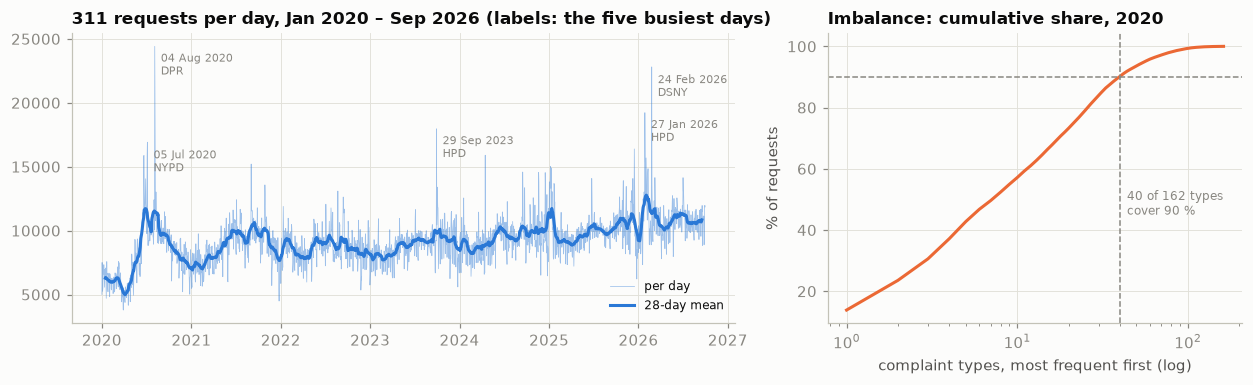

In [3]:
spikes = {}
for d_, v in daily.ALL.sort_values(ascending=False).items():          # the five busiest days, at least ten days apart
    if all(abs((d_ - k).days) > 10 for k in spikes):
        spikes[d_] = v
    if len(spikes) == 5:
        break
spikes = pd.Series(spikes)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.plot(daily.index, daily.ALL, lw=0.5, color=SERIES[0], alpha=0.45, label="per day")
ax.plot(daily.index, daily.ALL.rolling(28, center=True).mean(), lw=2, color=SERIES[0], label="28-day mean")
for d_, v in spikes.items():
    top = daily.loc[d_].drop("ALL").idxmax()
    ax.annotate(f"{d_:%d %b %Y}\n{top}", (d_, v), xytext=(4, -4), textcoords="offset points", fontsize=7, color=MUTED, va="top")
ax.set_title("311 requests per day, Jan 2020 – Sep 2026 (labels: the five busiest days)"); ax.legend(fontsize=8, loc="lower right")
ax = axes[1]
tt = rq[rq.created_date < TRAIN_END].complaint_type.value_counts(normalize=True)
ax.plot(np.arange(1, len(tt) + 1), tt.cumsum().values * 100, lw=2, color=SERIES[1])
n90 = int((tt.cumsum() < 0.9).sum()) + 1
ax.axhline(90, color=MUTED, ls="--", lw=1); ax.axvline(n90, color=MUTED, ls="--", lw=1)
ax.text(n90 + 4, 45, f"{n90} of {len(tt)} types\ncover 90 %", fontsize=8, color=MUTED)
ax.set_xscale("log"); ax.set_xlabel("complaint types, most frequent first (log)"); ax.set_ylabel("% of requests")
ax.set_title("Imbalance: cumulative share, 2020")
plt.tight_layout()

ag = rq.agency.value_counts(normalize=True)
print(f"mean requests per day: 2020 {daily.ALL[:'2020'].mean():,.0f} · 2025 {daily.ALL['2025'].mean():,.0f} · "
      f"Jan–Sep 2026 {daily.ALL['2026'].mean():,.0f} · lowest day {daily.ALL.min():,.0f} ({daily.ALL.idxmin():%d %b %Y})")
top_type = lambda d_: rq[rq.created_date.dt.normalize() == d_].complaint_type.value_counts().index[0]
print("busiest days:", " · ".join(f"{d_:%d %b %Y} {v:,.0f} ({daily.loc[d_].drop('ALL').idxmax()} {daily.loc[d_].drop('ALL').max():,.0f}; "
                                   f"top sampled type {top_type(d_)})" for d_, v in spikes.items()))
placeholder = rq.descriptor.isin(["", "N/A"])
print(f"descriptor is a placeholder (blank or 'N/A') for {placeholder.mean():.1%} of requests, e.g. "
      + ", ".join(rq[placeholder].complaint_type.value_counts().head(4).index))
print(f"agencies: {rq.agency.nunique()} · NYPD {ag['NYPD']:.1%}, HPD {ag['HPD']:.1%}, DSNY {ag['DSNY']:.1%} · "
      f"top type in 2020: {tt.index[0]} ({tt.iloc[0]:.1%}) · types with < 0.5 % each: {(tt < FREQUENT_SHARE).sum()} "
      f"({tt[tt < FREQUENT_SHARE].sum():.1%} of requests)")

In [4]:
# "First time right" today: closures that say the request was outside the agency's remit or passed to another body
BOUNCE = re.compile(r"jurisdiction|referred (?:it |this complaint |the complaint |this request |your request )?to (?:the (?:Department|New York|NYPD|NYC|Office|Metropolitan|Police)|another agency|DHS|NYPD)"
                    r"|forwarded the request to|will be referred to the (?:NYPD|appropriate agency)", re.I)
closed = rq[rq.status == "Closed"].copy()
NOT_A_BOUNCE = re.compile(r"no city agency has the jurisdiction|referred to the Department of Consumer Affairs\. There was"
                          r"|(?:investigated|attempted to investigate) or referred to another agency", re.I)   # self-referrals, nobody's remit
def bounced(texts: pd.Series) -> pd.Series:
    return texts.str.contains(BOUNCE) & ~texts.str.contains(NOT_A_BOUNCE)
closed["bounced"] = bounced(closed.resolution_description)
closed["days_to_close"] = (closed.closed_date - closed.created_date).dt.total_seconds() / 86400
bt = closed.groupby("agency").agg(requests=("bounced", "size"), bounced=("bounced", "mean"),
                                  median_days_to_close=("days_to_close", "median"))
bt = bt[bt.requests >= 500].sort_values("bounced", ascending=False)
FTR = 1 - closed.bounced.mean()
print(f"closed requests whose closure says 'not ours' or 'referred to another agency': {closed.bounced.mean():.2%} "
      f"(≈ {closed.bounced.mean() * daily.ALL['2025'].mean():,.0f} a day at the 2025 volume) · first time right ≈ {FTR:.1%}")
for a in ["EDC", "DSNY"]:
    print(f"most common 'not ours' closure, {a}:", closed[closed.bounced & (closed.agency == a)].resolution_description.value_counts().index[0].replace("\u00c2\u00a0", " ")[:205] + "…")   # the source has encoding debris
bt.style.format({"requests": "{:,}", "bounced": "{:.1%}", "median_days_to_close": "{:.2f}"})

closed requests whose closure says 'not ours' or 'referred to another agency': 2.79% (≈ 279 a day at the 2025 volume) · first time right ≈ 97.2%
most common 'not ours' closure, EDC: The New York City Economic Development Corporation determined that this issue is not within its jurisdiction because the helicopter did not belong to a tour company departing from a NYC heliport.  Instead,…
most common 'not ours' closure, DSNY: The Department of Sanitation does NOT have jurisdiction over vehicles (abandoned or otherwise) that have license plates affixed to them. Your request will be referred to the NYPD for further action.…


,requests,bounced,median_days_to_close
agency,,,
EDC,"2,799",90.7%,65.59
OSE,"1,352",14.9%,0.87
DCWP,"2,472",14.3%,1.95
DHS,"5,959",6.1%,0.22
DSNY,"50,426",6.1%,2.15
DPR,"14,974",4.4%,19.89
DCA,544,2.9%,1.56
DOB,"12,814",2.6%,10.50
DOT,"28,659",2.3%,1.82


Volume grew from 8,038 requests a day in 2020 to 10,014 in 2025 and 10,953 in 2026 so far. The busiest days are weather and fireworks: Tropical Storm Isaias on 4 Aug 2020 (16,093 requests to Parks, *Damaged Tree* above all), winter storms in 2026, the flash floods of 29 Sep 2023 (dates: National Weather Service). Forty of 162 types cover 90 % of requests.

**First time right today is at most about 97.2 %.** 2.79 % of closed requests end with a text saying the issue is outside the agency's remit or was passed on, about 279 a day. EDC bounces 91 % (helicopter noise: it handles only tour flights from city heliports), DSNY 6 % (derelict vehicles with plates belong to the NYPD). HPD never uses such wording and counts as right, so 97.2 % is an upper bound. The signal is late: a median of 0.04 days to close for NYPD, 20 for Parks, 66 for EDC.

# Part B — The given model

*Sections 3–6: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · The taxonomy as a knowledge base, and a router that reads it

*Part B · Given model · package `kb_snapshot`, `owner`, `route_agency` and `reply_context`; E1 rebuilds this catalogue as a graph.*

The catalogue is the knowledge base: **agency → complaint type → descriptor**, each entry dated by its first and last use. Every question is asked *as of a date*: an entry exists from its first use and retires once its last use in the whole window lies `KB_ACTIVE_DAYS` behind (a small look-ahead: an entry silent for 90 days, then reused, stays live). Four competency questions: who owns this type today, which types can this descriptor belong to, what changed this month, which entries are possible emergencies?

In [5]:
kb = tax.copy()
kb["first_day"], kb["last_day"] = kb.first_seen.dt.normalize(), kb.last_seen.dt.normalize()
assert (kb.first_seen <= kb.last_seen).all()

def kb_snapshot(day: pd.Timestamp) -> pd.DataFrame:
    """The catalogue as known on `day`: entries seen before that day and not silent for KB_ACTIVE_DAYS."""
    return kb[(kb.first_day < day) & (kb.last_day >= day - pd.Timedelta(days=KB_ACTIVE_DAYS))]

MONTHLY = (rq.assign(month=rq.created_date.dt.to_period("M")).groupby(["month", "agency", "complaint_type", "descriptor"])
           .size().rename("k").reset_index())
KEYS = ["agency", "complaint_type", "descriptor"]

def owner(day: pd.Timestamp) -> tuple[dict, dict]:
    """(type, descriptor) -> agency and type -> agency on `day`: among live catalogue entries, the agency that handled most
    sampled requests in the previous KB_ACTIVE_DAYS; with no recent traffic, the newest entry (agencies get renamed)."""
    snap = kb_snapshot(day)
    lo, hi = (day - pd.Timedelta(days=KB_ACTIVE_DAYS)).to_period("M"), (day - pd.Timedelta(days=1)).to_period("M")
    recent = MONTHLY[(MONTHLY.month >= lo) & (MONTHLY.month <= hi)].groupby(KEYS).k.sum().reset_index()
    s_ = snap.merge(recent, on=KEYS, how="left").fillna({"k": 0}).sort_values(["k", "first_seen"])
    by_type = s_.groupby(["complaint_type", "agency"]).agg(k=("k", "sum"), f=("first_seen", "max")).reset_index().sort_values(["k", "f"])
    return s_.groupby(["complaint_type", "descriptor"]).agency.last().to_dict(), by_type.groupby("complaint_type").agency.last().to_dict()

def assign_agency(df: pd.DataFrame, types, mode: str = "live") -> np.ndarray:
    """The owning agency of each (type, descriptor): from the 2020 majority ('train') or the catalogue month by month ('live')."""
    types = np.asarray(types, dtype=object)
    if mode == "train":
        o_td, o_t = OWNER_TRAIN
        return np.array([o_td.get((t, d), o_t.get(t, "?")) for t, d in zip(types, df.descriptor.values)], dtype=object)
    out = np.empty(len(df), dtype=object)
    for mo, ix in pd.Series(np.arange(len(df))).groupby(df.created_date.dt.to_period("M").to_numpy()):
        o_td, o_t = owner(mo.to_timestamp())
        ix = ix.values
        out[ix] = [o_td.get((t, d), o_t.get(t, "?")) for t, d in zip(types[ix], df.descriptor.values[ix])]
    return out

EMERGENCY = re.compile(r"(?<!non-)emergenc|gas (?:leak|hook-up|piping)|carbon monoxide(?! detector)|structural|shaking|collaps|"
                       r"falling|cave-in|chemical (?:spill|vapou?r)|oil spill|manhole cover missing|sparking|downed", re.I)   # policy list: 311 owns it
kb["emergency"] = (kb.complaint_type + " " + kb.descriptor).str.contains(EMERGENCY)

snap_cut = kb_snapshot(TRAIN_END)
d2t = kb.groupby("descriptor").complaint_type.nunique()
print(f"catalogue Jan 2020 – Sep 2026: {kb.agency.nunique()} agencies · {kb.complaint_type.nunique()} complaint types · "
      f"{kb.descriptor.nunique():,} descriptors · {len(kb):,} entries; as known on {TRAIN_END:%d %b %Y}: {len(snap_cut):,} entries, "
      f"{snap_cut.complaint_type.nunique()} types")
print(f"descriptors filed under more than one type: {(d2t > 1).sum()} ({kb[kb.descriptor.isin(d2t[d2t > 1].index)].n.sum() / kb.n.sum():.0%} of requests)")
# competency questions the router and the reply drafter ask of the catalogue
cq = {}
for day in ["2020-06-01", "2020-12-01"]:
    cq[f"CQ1 · who owns 'Consumer Complaint' on {day}?"] = owner(pd.Timestamp(day))[1].get("Consumer Complaint")
cq["CQ2 · which types can 'Loud Music/Party' be filed under?"] = sorted(kb_snapshot(TEST_END).query("descriptor == 'Loud Music/Party'").complaint_type)
sep21 = kb[(kb.first_day >= "2021-09-15") & (kb.first_day < "2021-10-01")]
cq["CQ3 · types first seen 15–30 Sep 2021 (DSNY)"] = f"{sep21.complaint_type.nunique()} types, {sep21.descriptor.nunique()} descriptors"
cq["CQ4 · catalogue entries flagged as possible emergencies (911 handover)"] = (
    f"{int(kb.emergency.sum())} entries, {kb.loc[kb.emergency, 'n'].sum() / kb.n.sum():.1%} of requests")
for q, a in cq.items():
    print(f"{q}: {a}")

catalogue Jan 2020 – Sep 2026: 21 agencies · 276 complaint types · 1,362 descriptors · 1,744 entries; as known on 01 Jan 2021: 1,056 entries, 194 types
descriptors filed under more than one type: 128 (40% of requests)
CQ1 · who owns 'Consumer Complaint' on 2020-06-01?: DCA
CQ1 · who owns 'Consumer Complaint' on 2020-12-01?: DCWP
CQ2 · which types can 'Loud Music/Party' be filed under?: ['Noise - Commercial', 'Noise - House of Worship', 'Noise - Park', 'Noise - Residential', 'Noise - Street/Sidewalk']
CQ3 · types first seen 15–30 Sep 2021 (DSNY): 19 types, 57 descriptors
CQ4 · catalogue entries flagged as possible emergencies (911 handover): 39 entries, 0.9% of requests


*Consumer Complaint* passes from DCA to DCWP, *Loud Music/Party* belongs to five noise types, and DSNY's rebuild added 19 types and 57 descriptors in late September 2021.

**What is known at intake.** The type is picked first, then a descriptor from that type's menu; location types are menus too (68 % of requests with one use a value that a single agency uses). So there are two honest questions. *Given the type*, which agency owns this entry today? That is the router: TF-IDF over the type and descriptor words plus one-hot location fields into a linear SVM (2,055 distinct training rows), overruled by the catalogue's owner wherever the catalogue, frozen at the cut or live as of the day before, knows the entry. *Before the type*, what do the channel, the borough and the clock say? The cell also prints what a reply drafter would receive.

In [6]:
CAT = ["location_type", "address_type"]
tr = rq.created_date < TRAIN_END
va = (rq.created_date >= TRAIN_END) & (rq.created_date < VALID_END)
te = (rq.created_date >= VALID_END) & (rq.created_date < TEST_END)
stream = rq.created_date >= TEST_END

def entry_text(df: pd.DataFrame) -> pd.Series:
    """The catalogue entry chosen at intake: complaint type plus descriptor words."""
    return (df.complaint_type + " " + df.descriptor + " " + df.descriptor_2).str.lower()

def descriptor_text(df: pd.DataFrame) -> pd.Series:
    return (df.descriptor + " " + df.descriptor_2).str.lower()

def fit_text(df: pd.DataFrame, target: str, text: pd.Series) -> dict:
    """TF-IDF on words plus one-hot location fields, into a linear SVM; identical rows collapsed into weights (same fit, fast)."""
    X_ = df[CAT].assign(text=text.values, y=df[target].values)
    g = X_.groupby(list(X_.columns), dropna=False).size().rename("w").reset_index()
    vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True); oh = OneHotEncoder(handle_unknown="ignore")
    clf = LinearSVC(C=0.5, max_iter=5000).fit(hstack([vec.fit_transform(g.text), oh.fit_transform(g[CAT])]).tocsr(), g.y, sample_weight=g.w)
    return {"vec": vec, "oh": oh, "clf": clf, "n_distinct": len(g)}

def predict_text(m: dict, df: pd.DataFrame, text: pd.Series) -> np.ndarray:
    X_ = df[CAT].assign(text=text.values)
    u = X_.drop_duplicates().reset_index(drop=True)
    idx = X_.merge(u.reset_index(), on=list(X_.columns), how="left")["index"].values
    return m["clf"].predict(hstack([m["vec"].transform(u.text), m["oh"].transform(u[CAT])]).tocsr())[idx].astype(object)

def known_entry(df: pd.DataFrame, asof=None) -> np.ndarray:
    """Is the (type, descriptor) entry in the catalogue as known the day before each request (live), or on a fixed day (frozen)?"""
    q = pd.DataFrame({"complaint_type": df.complaint_type.values, "descriptor": df.descriptor.values,
                      "day": df.created_date.dt.normalize().values if asof is None else asof})
    m_ = q.reset_index().merge(kb[["complaint_type", "descriptor", "first_day", "last_day"]], on=["complaint_type", "descriptor"], how="left")
    ok = (m_.first_day < m_.day) & (m_.last_day >= m_.day - pd.Timedelta(days=KB_ACTIVE_DAYS))
    return ok.groupby(m_["index"]).any().reindex(range(len(df)), fill_value=False).to_numpy(bool)

def route_agency(df: pd.DataFrame, kb_mode=None) -> np.ndarray:
    """Agency for the entry chosen at intake: the classifier alone, or the catalogue's owner wherever the catalogue
    (frozen at TRAIN_END, or live as of the day before) knows the entry, with the classifier as fallback."""
    cls = predict_text(router, df, entry_text(df))
    if kb_mode is None:
        return cls
    own = assign_agency(df, df.complaint_type, "train" if kb_mode == "frozen" else "live")
    ok = known_entry(df, TRAIN_END if kb_mode == "frozen" else None)
    return np.where(ok & (own != "?"), own, cls)

OWNER_TRAIN = (rq[tr].groupby(["complaint_type", "descriptor"]).agency.agg(lambda x: x.value_counts().index[0]).to_dict(),
               rq[tr].groupby("complaint_type").agency.agg(lambda x: x.value_counts().index[0]).to_dict())
t0 = time.time()
router = fit_text(rq[tr], "agency", entry_text(rq[tr]))
print(f"train {tr.sum():,} · valid {va.sum():,} · test {te.sum():,} · stream {stream.sum():,} sampled requests · "
      f"{len(router['clf'].classes_)} agencies · {router['n_distinct']:,} distinct training rows · fitted in {time.time() - t0:.1f}s")
lt = rq[tr & (rq.location_type != "")].groupby("location_type").agency.agg(lambda x: x.value_counts(normalize=True).iloc[0])
w_ = rq[tr & (rq.location_type != "")].location_type.value_counts()
print(f"menus inside the type: {w_[lt >= 0.99].sum() / w_.sum():.0%} of requests with a location type use one that a single agency "
      f"(≥ 99 %) uses; {(d2t > 1).sum()} of {len(d2t):,} descriptors appear under more than one type")

# What a reply drafter (task S1) may see: the routed catalogue entry and the agency's own standard closures — never a location
std = (rq[tr & (rq.resolution_description != "")].groupby(["agency", "complaint_type"]).resolution_description
       .agg(lambda x: x.value_counts().index[:2].tolist()))
def reply_context(agency: str, ctype: str, descriptor: str) -> dict:
    handover = bool(EMERGENCY.search(f"{ctype} {descriptor}"))       # deterministic guard, before any generation
    return {"agency": agency, "complaint_type": ctype, "descriptor": descriptor, "handover_911": handover,
            "standard_closures": [] if handover else [t[:140] + "…" for t in std.get((agency, ctype), [])]}
for ex_ in [("DOT", "Street Condition", "Pothole"), ("DEP", "Sewer", "Manhole Cover Missing (Emergency) (SA3)")]:
    print(reply_context(*ex_))

train 58,850 · valid 13,482 · test 28,063 · stream 352,837 sampled requests · 17 agencies · 2,055 distinct training rows · fitted in 0.7s
menus inside the type: 68% of requests with a location type use one that a single agency (≥ 99 %) uses; 128 of 1,362 descriptors appear under more than one type


{'agency': 'DOT', 'complaint_type': 'Street Condition', 'descriptor': 'Pothole', 'handover_911': False, 'standard_closures': ['The Department of Transportation inspected this complaint and repaired the problem.…', 'The Department of Transportation inspected and has requested the Department of Environmental Protection address the issue. The condition wil…']}
{'agency': 'DEP', 'complaint_type': 'Sewer', 'descriptor': 'Manhole Cover Missing (Emergency) (SA3)', 'handover_911': True, 'standard_closures': []}


## 4 · Honest evaluation forward in time, and the operating point

*Part B · Given model · package `metrics`, `risk` and `desk_curve`; reproduce the holdout (C2); C3 owns the desk threshold.*

Trained on 2020; variant, desk threshold and gates set on January–March 2021; April–August 2021 is the frozen holdout. Metrics: agency accuracy, and macro-F1 over the **frequent** agencies (at least 0.5 % of 2020 requests and still in use).

In [7]:
FREQ_AGENCIES = [k for k, v in rq[tr].agency.value_counts(normalize=True).items() if v >= FREQUENT_SHARE]
FREQ_TYPES = [k for k, v in rq[tr].complaint_type.value_counts(normalize=True).items() if v >= FREQUENT_SHARE]

def metrics(y, p, freq) -> dict:
    y, p = np.asarray(y), np.asarray(p, dtype=object)
    labels = [c for c in freq if c in set(y)]                          # frequent and still in use
    f = np.isin(y, labels)
    return {"accuracy": accuracy_score(y, p), "macro-F1 (frequent)": f1_score(y[f], p[f], labels=labels, average="macro", zero_division=0)}

# what precedes the type decision: channel, borough and the clock (LightGBM, no words, no menu fields)
PRE_TYPE = ["open_data_channel_type", "borough"]
LGB_CLS = dict(n_estimators=200, learning_rate=0.05, num_leaves=31, min_child_samples=30, random_state=SEED, verbose=-1, n_jobs=N_JOBS)   # at 0.1 the multiclass fit with categorical splits diverges
def pre_type_X(df: pd.DataFrame, extra=()) -> pd.DataFrame:
    X = pd.DataFrame(index=df.index)
    for c in list(PRE_TYPE) + list(extra):
        cats = sorted(rq.loc[tr, c].unique())                              # values unseen in 2020 become missing
        X[c] = pd.Categorical(df[c].where(df[c].isin(cats)), categories=cats)
    X["hour"], X["dow"], X["month"] = df.created_date.dt.hour, df.created_date.dt.day_of_week, df.created_date.dt.month
    return X
def fit_pre(target: str, extra=(), class_weight=None, frame=None):
    d = rq[tr] if frame is None else frame
    y = d[target]; keep = (y.map(y.value_counts()) >= 30).values           # classes with at least 30 training requests
    return lgb.LGBMClassifier(**LGB_CLS, class_weight=class_weight).fit(pre_type_X(d, extra)[keep], y[keep])

t0 = time.time()
pre_router = fit_pre("agency")
VARIANTS = {"given the type · lookup: the entry's owner in 2020": lambda d: assign_agency(d, d.complaint_type, "train"),
            "given the type · classifier (type and descriptor words)": lambda d: route_agency(d, None),
            "given the type · classifier + catalogue frozen at the cut": lambda d: route_agency(d, "frozen"),
            "given the type · classifier + live catalogue (day before)": lambda d: route_agency(d, "live"),
            "before the type · channel, borough, time (LightGBM)": lambda d: pre_router.predict(pre_type_X(d)),
            "before the type · always the busiest agency (NYPD)": lambda d: np.full(len(d), rq[tr].agency.mode()[0], dtype=object)}
ev = pd.DataFrame({(split, name): metrics(rq.loc[m_, "agency"], f(rq[m_]), FREQ_AGENCIES)
                   for split, m_ in [("valid", va), ("test", te)] for name, f in VARIANTS.items()}).T
display(ev.style.format("{:.3f}"))
LIVE, LOOKUP = "given the type · classifier + live catalogue (day before)", "given the type · lookup: the entry's owner in 2020"
print("CI gate (relative to the incumbent on the same months): router agency accuracy ≥ the 2020 lookup's · "
      + " · ".join(f"{s_} {ev.loc[(s_, LIVE), 'accuracy']:.2%} against {ev.loc[(s_, LOOKUP), 'accuracy']:.2%}" for s_ in ["valid", "test"]))
print(f"frequent agencies (≥ {FREQUENT_SHARE:.1%} of 2020): {', '.join(FREQ_AGENCIES)} · entries unknown to the 2020 catalogue: "
      f"valid {(~known_entry(rq[va], TRAIN_END)).mean():.1%}, test {(~known_entry(rq[te], TRAIN_END)).mean():.1%} · {time.time() - t0:.0f}s")

CI gate (relative to the incumbent on the same months): router agency accuracy ≥ the 2020 lookup's · valid 99.96% against 99.47% · test 99.73% against 99.07%
frequent agencies (≥ 0.5% of 2020): NYPD, DSNY, HPD, DOT, DPR, DEP, DOB, DOHMH, OSE, DCA, DHS, TLC · entries unknown to the 2020 catalogue: valid 0.1%, test 0.4% · 26s


**Given the type, routing is the catalogue.** The 2020 owner of each entry is right for 99.1 % of test requests, the classifier for 99.1 %, the live catalogue for 99.7 %: it knows DSNY's first new entries of May 2021 the next day, and that DCA is now DCWP. That figure is agreement with the catalogue's routing, so it cannot beat the bounces of Section 2. **Before the type, a model knows little**: channel, borough and time give 58.6 % (macro-F1 0.23), against 45.4 % for always answering NYPD.

**The routing desk.** The lever on first time right is catching bounces early: each request is scored by its entry's 2020 bounce rate (shrunk towards its type's), and the desk checks the highest scores. A check costs `COST_REVIEW_USD`, a bounce `COST_WRONG_AGENCY_USD`, and the desk fixes `DESK_FIX_RATE` of those it sees (assumptions). The threshold maximises the daily saving on validation within capacity and is applied unchanged to test. Each sampled request stands for 50.

,checks/day,bounces/day,caught/day,precision,recall,saving/day
validation (at the chosen threshold),250,163,91,36.2%,55.6%,"$2,217"
test (same threshold),205,226,108,52.4%,47.5%,"$2,815"


test AUPRC (bounce rate 2.51%): entry's 2020 bounce rate 0.498 · LightGBM on entry and context 0.346
checks per day by test month: {'Apr': 213, 'May': 229, 'Jun': 223, 'Jul': 176, 'Aug': 185} · top flagged types: {'Derelict Vehicles': 367, 'Noise - Helicopter': 188, 'NonCompliance with Phased Reopening': 53}


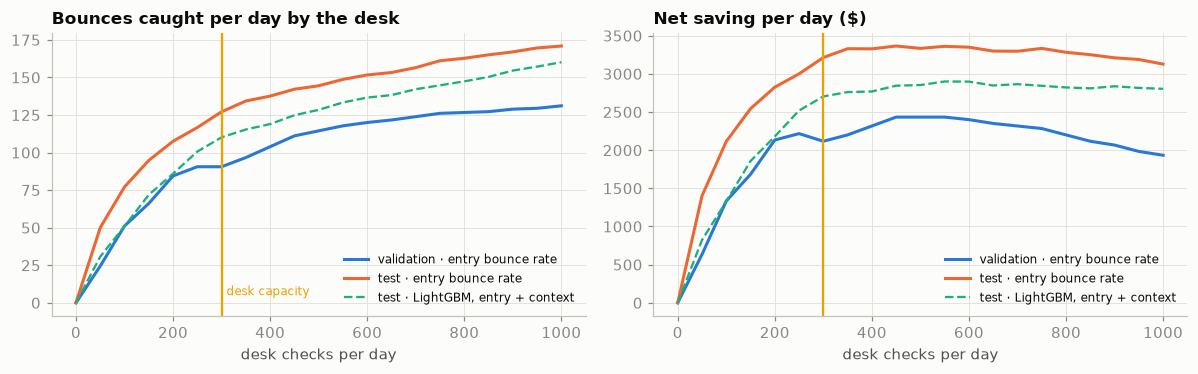

In [8]:
# The operating point: the routing desk checks the requests most likely to bounce, before an agency sees them.
# Label: the closure says "not ours" or "referred" (known only after closure). Score: the entry's bounce rate in 2020.
rq["bounced"] = bounced(rq.resolution_description) & (rq.status == "Closed")
cl_tr = tr & (rq.status == "Closed")
base = rq.loc[cl_tr, "bounced"].mean()
by_type = rq[cl_tr].groupby("complaint_type").bounced.agg(["sum", "size"])
rate_type = (by_type["sum"] + 20 * base) / (by_type["size"] + 20)                     # shrunk towards the overall rate
by_entry = rq[cl_tr].groupby(["complaint_type", "descriptor"]).bounced.agg(["sum", "size"]).reset_index()
by_entry["rate"] = (by_entry["sum"] + 20 * by_entry.complaint_type.map(rate_type)) / (by_entry["size"] + 20)
def risk(df: pd.DataFrame) -> np.ndarray:
    r = df[["complaint_type", "descriptor"]].merge(by_entry[["complaint_type", "descriptor", "rate"]], how="left").rate.to_numpy()
    return np.where(np.isnan(r), df.complaint_type.map(rate_type).fillna(base).to_numpy(), r)

CTX = ["complaint_type", "descriptor", "location_type", "address_type"]          # the comparison: entry + context, LightGBM
ctx_model = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=40, min_data_per_group=50,
                               cat_smooth=20, reg_lambda=5.0, random_state=SEED, verbose=-1, n_jobs=N_JOBS
                               ).fit(pre_type_X(rq[cl_tr], CTX), rq.loc[cl_tr, "bounced"])

def desk_curve(df: pd.DataFrame, score: np.ndarray, n_days: int) -> pd.DataFrame:
    y = df.bounced.to_numpy(); order = np.argsort(-score)
    rows = []
    for per_day in np.r_[0, np.arange(50, 1001, 50)]:
        k = int(round(per_day * n_days / SCALE)); top = order[:k]
        caught = y[top].sum() * SCALE / n_days
        rows.append({"checks/day": per_day, "bounces/day": y.sum() * SCALE / n_days, "caught/day": caught,
                     "precision": y[top].mean() if k else np.nan, "recall": y[top].sum() / y.sum(),
                     "saving/day": caught * DESK_FIX_RATE * COST_WRONG_AGENCY_USD - per_day * COST_REVIEW_USD,
                     "thr": score[order[k - 1]] if k else np.inf})
    return pd.DataFrame(rows)

cl_va, cl_te = va & (rq.status == "Closed"), te & (rq.status == "Closed")
dc_va = desk_curve(rq[cl_va], risk(rq[cl_va]), days_va := (VALID_END - TRAIN_END).days)
feas = dc_va[dc_va["checks/day"] <= REVIEW_CAPACITY_PER_DAY]
THR = float(feas.loc[feas["saving/day"].idxmax(), "thr"])                          # chosen on validation, frozen
s_te = risk(rq[cl_te]); days_te = (TEST_END - VALID_END).days
dc_te = desk_curve(rq[cl_te], s_te, days_te)
flag = s_te >= THR
y_te = rq.loc[cl_te, "bounced"].to_numpy()
op = pd.DataFrame({
    "validation (at the chosen threshold)": feas.loc[feas["saving/day"].idxmax(), ["checks/day", "bounces/day", "caught/day", "precision", "recall", "saving/day"]],
    "test (same threshold)": pd.Series({"checks/day": flag.sum() * SCALE / days_te, "bounces/day": y_te.sum() * SCALE / days_te,
                                        "caught/day": y_te[flag].sum() * SCALE / days_te, "precision": y_te[flag].mean(),
                                        "recall": y_te[flag].sum() / y_te.sum(),
                                        "saving/day": y_te[flag].sum() * SCALE / days_te * DESK_FIX_RATE * COST_WRONG_AGENCY_USD
                                                      - flag.sum() * SCALE / days_te * COST_REVIEW_USD})}).T
display(op.style.format({"checks/day": "{:,.0f}", "bounces/day": "{:,.0f}", "caught/day": "{:,.0f}", "precision": "{:.1%}",
                         "recall": "{:.1%}", "saving/day": "${:,.0f}"}))
p_ctx = ctx_model.predict_proba(pre_type_X(rq[cl_te], CTX))[:, 1]
print(f"test AUPRC (bounce rate {y_te.mean():.2%}): entry's 2020 bounce rate {average_precision_score(y_te, s_te):.3f} · "
      f"LightGBM on entry and context {average_precision_score(y_te, p_ctx):.3f}")
per_month = pd.Series(flag).groupby(rq.loc[cl_te, "created_date"].dt.to_period("M").to_numpy()).sum()
print("checks per day by test month:", {f"{m:%b}": round(v * SCALE / m.days_in_month) for m, v in per_month.items()},
      "· top flagged types:", rq.loc[cl_te][flag].complaint_type.value_counts().head(3).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
dc_ctx = desk_curve(rq[cl_te], p_ctx, days_te)
for ax, col, title in [(axes[0], "caught/day", "Bounces caught per day by the desk"), (axes[1], "saving/day", "Net saving per day ($)")]:
    ax.plot(dc_va["checks/day"], dc_va[col], lw=2, color=SERIES[0], label="validation · entry bounce rate")
    ax.plot(dc_te["checks/day"], dc_te[col], lw=2, color=SERIES[1], label="test · entry bounce rate")
    ax.plot(dc_ctx["checks/day"], dc_ctx[col], lw=1.5, ls="--", color=SERIES[2], label="test · LightGBM, entry + context")
    ax.axvline(REVIEW_CAPACITY_PER_DAY, color=SERIES[3], lw=1.5); ax.set_xlabel("desk checks per day")
    ax.set_title(title); ax.legend(fontsize=8)
axes[0].text(REVIEW_CAPACITY_PER_DAY + 10, 5, "desk capacity", color=SERIES[3], fontsize=8)
plt.tight_layout()

On validation the chosen threshold sends 250 requests a day to the desk and catches 91 of 163 daily bounces. On the test months it sends 205 a day and catches 108 of 226 (precision 52 %, recall 47 %), saving about $2,800 a day at the assumed costs. Two types fill the queue, *Derelict Vehicles* (with plates they are NYPD's) and *Noise - Helicopter* (federal unless a tour flight). A LightGBM on entry and context does worse than the catalogue's own rate (AUPRC 0.35 against 0.50): the risk sits in the catalogue entry, and the lasting fix is a question at intake (C3).

## 5 · Tomorrow's workload: a day-ahead forecast per agency

*Part B · Given model · package `fc_frame`, `fc_fit_predict` and `fc_scores` unchanged and reproduce the 2025 error (C2).*

Tomorrow's staffing is set this afternoon, so every input is at least `OBS_LAG_DAYS` = 2 days old. Baseline: the **seasonal naive**, same weekday last week. Model: one LightGBM over nine series (city and eight agencies) predicting the ratio to the last complete week's level from lags of 2–28 and 364 days, the trend, the calendar and US federal holidays; fitted to 2023 to score 2024, refitted to 2024 to score 2025.

In [9]:
HOLIDAYS = USFederalHolidayCalendar().holidays(WINDOW_START - pd.Timedelta(days=30), WINDOW_END + pd.Timedelta(days=30))

def fc_frame(obs_lag: int = OBS_LAG_DAYS) -> pd.DataFrame:
    """One row per (series, target day); every input uses days at least `obs_lag` days before the target."""
    out = []
    for a in daily.columns:
        y = daily[a]
        lvl = y.shift(obs_lag).rolling(7, min_periods=5).mean()          # level: the newest complete week
        f = pd.DataFrame({"day": daily.index, "series": a, "y": y.values, "level": lvl.values})
        for k in sorted({obs_lag, obs_lag + 1, 7, 14, 21, 28, 364}):
            f[f"lag{k}"] = (y.shift(k) / lvl).values
        f["trend"] = (lvl / y.shift(obs_lag).rolling(28, min_periods=20).mean()).values
        idx = daily.index
        f["dow"], f["month"], f["doy"] = idx.day_of_week, idx.month, idx.day_of_year
        f["holiday"] = idx.isin(HOLIDAYS).astype(int)
        f["after_holiday"] = (idx - pd.Timedelta(days=1)).isin(HOLIDAYS).astype(int)
        f["before_holiday"] = (idx + pd.Timedelta(days=1)).isin(HOLIDAYS).astype(int)
        out.append(f)
    F = pd.concat(out, ignore_index=True)
    F["series"] = F.series.astype("category")
    F["naive"] = F.groupby("series", observed=True).y.shift(7)           # same weekday last week
    return F

def fc_fit_predict(F: pd.DataFrame, train_mask, feats) -> np.ndarray:
    m = lgb.LGBMRegressor(**LGB_PARAMS).fit(F.loc[train_mask, feats], F.loc[train_mask, "y"] / F.loc[train_mask, "level"])
    return m.predict(F[feats]) * F.level.values, m

def fc_scores(F, pred, mask) -> pd.DataFrame:
    e = F[mask].assign(p=pred[mask.values])
    g = e.groupby("series", observed=True)
    return pd.DataFrame({"MAPE model": g.apply(lambda d: (abs(d.p - d.y) / d.y).mean(), include_groups=False),
                         "MAPE same weekday last week": g.apply(lambda d: (abs(d.naive - d.y) / d.y).mean(), include_groups=False),
                         "mean per day": g.y.mean()})

t0 = time.time()
F = fc_frame()
FEATS = [c for c in F.columns if c not in ("day", "y", "level", "naive")]
ok = F.y.notna() & (F.y > 0) & F.level.notna() & F.naive.notna()
fc_tr = ok & (F.day >= FC_TRAIN_START) & (F.day < FC_VALID_START)
fc_va = ok & (F.day >= FC_VALID_START) & (F.day < FC_TEST_START)
fc_te = ok & (F.day >= FC_TEST_START) & (F.day < FC_STREAM_START)
fc_st = ok & (F.day >= FC_STREAM_START)
print("days with no requests in the counts (left out of scoring):", {k: int(v) for k, v in daily.isna().sum().items() if v})
p_val, _ = fc_fit_predict(F, fc_tr, FEATS)                               # fitted to 2023: scores the validation year
p_fc, fc_model = fc_fit_predict(F, ok & (F.day >= FC_TRAIN_START) & (F.day < FC_TEST_START), FEATS)   # refitted to 2024: test, stream
res_va, res_te = fc_scores(F, p_val, fc_va), fc_scores(F, p_fc, fc_te)
res_te["better than naive"] = res_te["MAPE model"] < res_te["MAPE same weekday last week"]
display(res_te.style.format({"MAPE model": "{:.1%}", "MAPE same weekday last week": "{:.1%}", "mean per day": "{:,.0f}"}))
# paired bootstrap over weeks for the city-wide gap
e = F[fc_te & (F.series == "ALL")].assign(p=p_fc[(fc_te & (F.series == "ALL")).values])
gap = (abs(e.p - e.y) / e.y - abs(e.naive - e.y) / e.y).groupby(((e.day - FC_TEST_START).dt.days // 7).values).mean().values
rng = np.random.default_rng(SEED)
boot = np.array([rng.choice(gap, len(gap)).mean() for _ in range(2000)])
print(f"validation 2024 (model fitted to 2023): city-wide MAPE {res_va.loc['ALL', 'MAPE model']:.1%} against "
      f"{res_va.loc['ALL', 'MAPE same weekday last week']:.1%} · test 2025: model − naive {gap.mean():+.1%} per day, "
      f"95 % interval over weeks [{np.percentile(boot, 2.5):+.1%}, {np.percentile(boot, 97.5):+.1%}] · {time.time() - t0:.0f}s")

days with no requests in the counts (left out of scoring): {'HPD': 5, 'DOB': 2}


,MAPE model,MAPE same weekday last week,mean per day,better than naive
series,,,,
ALL,7.6%,10.1%,"10,014",True
DEP,13.5%,22.2%,540,True
DOB,14.8%,22.0%,282,True
DOHMH,9.5%,14.7%,228,True
DOT,10.7%,16.7%,581,True
DPR,18.1%,30.2%,304,True
DSNY,11.8%,21.2%,895,True
HPD,16.6%,23.2%,"2,122",True
NYPD,12.1%,13.9%,"4,706",True


validation 2024 (model fitted to 2023): city-wide MAPE 8.0% against 10.8% · test 2025: model − naive -2.4% per day, 95 % interval over weeks [-3.6%, -1.3%] · 4s


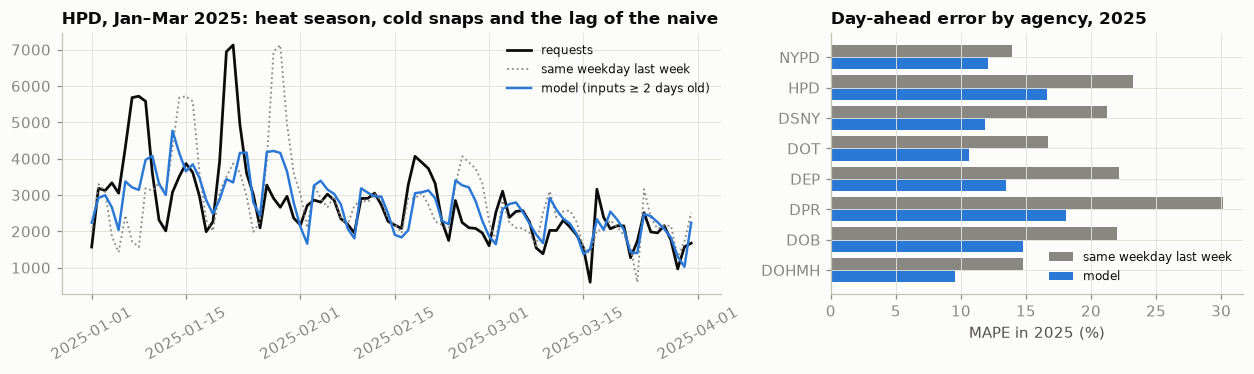

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.5), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
h = F[(F.series == "HPD") & (F.day >= "2025-01-01") & (F.day < "2025-04-01")]
ph = p_fc[h.index.values]
ax.plot(h.day, h.y, color=INK, lw=1.8, label="requests")
ax.plot(h.day, h.naive, color=MUTED, lw=1.2, ls=":", label="same weekday last week")
ax.plot(h.day, ph, color=SERIES[0], lw=1.6, label=f"model (inputs ≥ {OBS_LAG_DAYS} days old)")
ax.set_title("HPD, Jan–Mar 2025: heat season, cold snaps and the lag of the naive"); ax.legend(fontsize=8)
ax.tick_params(axis="x", rotation=30)
ax = axes[1]
r_ = res_te.drop(index="ALL").sort_values("mean per day")
yy = np.arange(len(r_))
ax.barh(yy + 0.2, r_["MAPE same weekday last week"] * 100, height=0.4, color=MUTED, label="same weekday last week")
ax.barh(yy - 0.2, r_["MAPE model"] * 100, height=0.4, color=SERIES[0], label="model")
ax.set_yticks(yy); ax.set_yticklabels(r_.index); ax.set_xlabel("MAPE in 2025 (%)")
ax.set_title("Day-ahead error by agency, 2025"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()

City-wide, the model's 2025 error is **7.6 % against 10.1 %** for the seasonal naive (paired difference −2.4 points a day, 95 % interval over weeks [−3.6, −1.3]); validation told the same story (8.0 % against 10.8 %). It beats the naive for every agency, most for Parks (18.1 % against 30.2 %) and DSNY (11.8 % against 21.2 %). The HPD panel shows the mechanism: a cold snap doubles heat complaints, the naive repeats the spike a week late, and the model, whose newest input is two days old, follows it two days late. Neither sees a storm coming (E3).

## 6 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

Five careless choices, each measured against the honest one.

In [11]:
t0 = time.time()
trap_rows = []
y_ag = lambda m_: rq.loc[m_, "agency"].to_numpy()
acc = lambda m_, p: float(np.mean(np.asarray(p, dtype=object) == y_ag(m_)))
p_pre = pre_router.predict(pre_type_X(rq[te]))
honest_pre = acc(te, p_pre)
# Trap 1 — closure fields used at intake: the agency's closing text (a template, so a category) in the before-the-type router
leaky = fit_pre("agency", extra=["resolution_description"])
trap_rows.append(("Trap 1 · closing text as a feature (before the type)", "agency accuracy",
                  acc(te, leaky.predict(pre_type_X(rq[te], ["resolution_description"]))), honest_pre))
trap_rows.append(("Trap 1 · … the same model at intake, closing text blank", "agency accuracy",
                  acc(te, leaky.predict(pre_type_X(rq[te].assign(resolution_description=""), ["resolution_description"]))), honest_pre))
names_agency = rq.loc[tr & (rq.resolution_description != ""), "resolution_description"].str.contains(
    r"Department|Police|NYPD|Parks|Sanitation|Economic Development|Commission|Office", case=False).mean()
open_at_snapshot = (rq.status != "Closed").groupby(rq.created_date.dt.year).mean()
# Trap 2 — fields picked inside the type's menu: location type, then the descriptor (the first version of this notebook)
LOC = ["location_type", "address_type"]
loc_router = fit_pre("agency", extra=LOC)
trap_rows.append(("Trap 2 · + location type (its menu depends on the type)", "agency accuracy",
                  acc(te, loc_router.predict(pre_type_X(rq[te], LOC))), honest_pre))
desc_router = fit_text(rq[tr], "agency", descriptor_text(rq[tr]))
trap_rows.append(("Trap 2 · + descriptor words (picked inside the type's menu)", "agency accuracy",
                  acc(te, predict_text(desc_router, rq[te], descriptor_text(rq[te]))), honest_pre))
rq["type_frequent"] = rq.complaint_type.where(rq.complaint_type.isin(FREQ_TYPES), "(other)")
type_pre = fit_pre("type_frequent")
type_desc = fit_text(rq[tr], "complaint_type", descriptor_text(rq[tr]))
y_ty = rq.loc[te, "complaint_type"].to_numpy()
trap_rows.append(("Trap 2 · the complaint type itself: from the descriptor vs from channel, borough, time", "type accuracy",
                  np.mean(predict_text(type_desc, rq[te], descriptor_text(rq[te])) == y_ty), np.mean(type_pre.predict(pre_type_X(rq[te])) == y_ty)))
# Trap 3 — imbalance: the before-the-type router's accuracy is mostly NYPD
m_pre = metrics(y_ag(te), p_pre, FREQ_AGENCIES)
bal = fit_pre("agency", class_weight="balanced"); m_bal = metrics(y_ag(te), bal.predict(pre_type_X(rq[te])), FREQ_AGENCIES)
trap_rows.append(("Trap 3 · before the type: accuracy vs macro-F1 over frequent agencies", "score", m_pre["accuracy"], m_pre["macro-F1 (frequent)"]))
trap_rows.append(("Trap 3 · … with balanced class weights", "score", m_bal["accuracy"], m_bal["macro-F1 (frequent)"]))
small = ~np.isin(y_ag(te), ["NYPD", "HPD", "DSNY"])
# Trap 4 — a label is renamed, and the random split that hides it (given the type)
cc = (rq.complaint_type == "Consumer Complaint") & stream                       # the true type: only the owner differs
trap_rows.append(("Trap 4 · 'Consumer Complaint' from Sep 2021: owner from 2020 vs live catalogue", "agency accuracy",
                  acc(cc, assign_agency(rq[cc], rq.loc[cc, "complaint_type"], "train")), acc(cc, assign_agency(rq[cc], rq.loc[cc, "complaint_type"], "live"))))
hpd23 = (rq.agency == "HPD") & (rq.created_date >= "2023-08-01") & (rq.created_date < "2023-11-01")
title_case = (rq.loc[hpd23, "complaint_type"] != rq.loc[hpd23, "complaint_type"].str.upper()).mean()
trap_rows.append(("Trap 4 · HPD Aug–Oct 2023, 2020 owner map: exact labels vs case-folded", "agency accuracy",
                  acc(hpd23, assign_agency(rq[hpd23], rq.loc[hpd23, "complaint_type"], "train")),
                  acc(hpd23, assign_agency(rq[hpd23], rq.loc[hpd23, "complaint_type"].str.upper(), "train"))))
perm = np.random.default_rng(SEED).permutation(len(rq)); cut = int(0.8 * len(rq))
rtr, rte = rq.iloc[np.sort(perm[:cut])], rq.iloc[np.sort(perm[cut:])]
acc_rand = float(np.mean(predict_text(fit_text(rtr, "agency", entry_text(rtr)), rte, entry_text(rte)) == rte.agency.to_numpy()))
r_cls_stream = route_agency(rq[stream], None)                                   # the classifier frozen in August 2021
trap_rows.append(("Trap 4 · given the type: random 80/20 split vs the frozen classifier, Sep 2021 – Sep 2026", "agency accuracy",
                  acc_rand, acc(stream, r_cls_stream)))
# Trap 5 — the forecast: yesterday's count is not complete when staffing is set; spikes decide the error
F1 = fc_frame(obs_lag=1)
p_lag1, _ = fc_fit_predict(F1, ok & (F1.day >= FC_TRAIN_START) & (F1.day < FC_TEST_START), [c for c in F1.columns if c not in ("day", "y", "level", "naive")])
m_all = (fc_te & (F.series == "ALL")).values
mape = lambda p, m: float((abs(p[m] - F.y.values[m]) / F.y.values[m]).mean())
trap_rows.append(("Trap 5 · forecast with yesterday's (incomplete) count, city-wide 2025", "MAPE", mape(p_lag1, m_all), mape(p_fc, m_all)))
ape = pd.Series(abs(p_fc[m_all] - F.y.values[m_all]) / F.y.values[m_all], index=F.day[m_all].values)
spike_days = ape.index[(F.y.values[m_all] > 1.25 * F.level.values[m_all])]
calm = ape.index[(ape.index.month >= 6) & (ape.index.month <= 8)]
trap_rows.append(("Trap 5 · city-wide 2025: summer months only vs the whole year", "MAPE", ape[calm].mean(), ape.mean()))
trap_rows.append((f"Trap 5 · city-wide 2025: ordinary days vs the {len(spike_days)} surge days (> 1.25 × last week's level)", "MAPE",
                  ape.drop(spike_days).mean(), ape[spike_days].mean()))
traps = pd.DataFrame(trap_rows, columns=["trap", "metric", "careless", "honest"]).set_index("trap")
display(traps.style.format({"careless": "{:.3f}", "honest": "{:.3f}"}))
print(f"closure texts that name an agency: {names_agency:.0%} · share still open at the snapshot: "
      + ", ".join(f"{y}: {v:.1%}" for y, v in open_at_snapshot.items()) + f" · trap fits in {time.time() - t0:.0f}s")
print(f"before the type: {np.mean(p_pre == 'NYPD'):.0%} of predictions are NYPD; recall on agencies other than NYPD, HPD and DSNY "
      f"({small.mean():.0%} of test requests): {np.mean(p_pre[small] == y_ag(te)[small]):.1%}")
tc = kb[(kb.agency == "HPD") & (kb.complaint_type != kb.complaint_type.str.upper())]
bulk, late = tc[tc.last_seen < "2024-01-01"], tc[tc.last_seen >= "2024-01-01"]
flood = rq[(rq.created_date.dt.normalize() == "2023-09-29") & rq.complaint_type.str.upper().eq("WATER LEAK")].complaint_type.value_counts()
print(f"HPD title-case labels: {bulk.n.sum():,} requests {bulk.first_seen.min():%d %b} – {bulk.last_seen.max():%d %b %Y}, then "
      f"{late.n.sum():,} more under {sorted(late.complaint_type.unique())} to {late.last_seen.max():%b %Y} · {title_case:.1%} of HPD requests "
      f"in Aug–Oct 2023 · 29 Sep 2023 in the sample: {flood.to_dict()}")

,metric,careless,honest
trap,,,
Trap 1 · closing text as a feature (before the type),agency accuracy,0.968,0.586
"Trap 1 · … the same model at intake, closing text blank",agency accuracy,0.182,0.586
Trap 2 · + location type (its menu depends on the type),agency accuracy,0.937,0.586
Trap 2 · + descriptor words (picked inside the type's menu),agency accuracy,0.988,0.586
"Trap 2 · the complaint type itself: from the descriptor vs from channel, borough, time",type accuracy,0.975,0.227
Trap 3 · before the type: accuracy vs macro-F1 over frequent agencies,score,0.586,0.230
Trap 3 · … with balanced class weights,score,0.319,0.203
Trap 4 · 'Consumer Complaint' from Sep 2021: owner from 2020 vs live catalogue,agency accuracy,0.160,1.000
"Trap 4 · HPD Aug–Oct 2023, 2020 owner map: exact labels vs case-folded",agency accuracy,0.921,1.000


closure texts that name an agency: 92% · share still open at the snapshot: 2020: 2.0%, 2021: 1.4%, 2022: 1.2%, 2023: 1.4%, 2024: 1.1%, 2025: 1.5%, 2026: 4.7% · trap fits in 156s
before the type: 61% of predictions are NYPD; recall on agencies other than NYPD, HPD and DSNY (26% of test requests): 13.7%
HPD title-case labels: 13,612 requests 10 Aug – 06 Oct 2023, then 1 more under ['Safety'] to Mar 2026 · 7.9% of HPD requests in Aug–Oct 2023 · 29 Sep 2023 in the sample: {'Water Leak': 39, 'WATER LEAK': 31}


**Trap 1 — closure fields at intake.** Give the before-the-type router the agency's closing text and it scores 96.8 % instead of 58.6 %. At intake, where that text is blank, the same model scores 18.2 %, worse than always answering NYPD.

**Trap 2 — fields chosen inside the type's menu.** Add location types to the before-the-type router: 93.7 %. Add descriptor words instead: 98.8 %. Predict the type from the descriptor: 97.5 %, against 22.7 % from channel, borough and time. These read the menu back: routing *given* the type.

**Trap 3 — accuracy hides the small agencies.** Before the type, 61 % of predictions are NYPD; on the 26 % of requests for agencies other than NYPD, HPD and DSNY the router is right 13.7 % of the time, and macro-F1 is 0.23. Balanced class weights do not rescue it (accuracy 31.9 %, macro-F1 0.20).

**Trap 4 — renamed labels, and the split that hides them.** From September 2021 *Consumer Complaint* goes to DCWP: the 2020 owner map (DCA) is right 16 % of the time, the live catalogue 100 %. HPD's title-case labels of August–October 2023 (7.9 % of HPD requests; *Water Leak* and *WATER LEAK* both appear on 29 September) are unknown keys to the 2020 map: 92.1 % right, 100 % case-folded. A random 80/20 split over 2020–2026 shows 99.7 %; the classifier frozen in August 2021 manages 96.1 % on what came next.

**Trap 5 — the forecast's flattering numbers.** Yesterday's count, incomplete when staffing is set, gives 6.3 % instead of 7.6 %. Summer alone gives 4.9 %. On the 14 surge days of 2025 (above 1.25 times the latest complete week's level) the error is 20.2 %, against 7.1 % on ordinary days.

# Part C — Productionise it

*Sections 7–10: this is your assignment.*

## 7 · After deployment: the catalogue moves under a frozen router

*Part C · Productionise · what your monitoring plan must catch; reuse `psi` (C5).*

Freeze the Section 4 routers on 31 August 2021 and run them to September 2026. On the right, three monitor signals: the share of requests filed under a catalogue entry less than 30 days old (same day), the type-mix PSI against the same month a year earlier (same season), and the bounce rate (once requests close).

stream scored in 13s · Sep 2021 – Sep 2026, agency accuracy by month: lookup: 2020 owners 86.1%–95.9% (mean 91.8%) · classifier 89.2%–98.2% (mean 96.1%) · classifier + frozen catalogue 91.4%–99.0% (mean 98.0%) · classifier + live catalogue 99.4%–99.9% (mean 99.7%) · bounced 1.3%–5.7% (mean 2.9%) · unknown entries 3.2%–16.5% (mean 8.6%)


,lookup: 2020 owners,classifier,classifier + frozen catalogue,classifier + live catalogue,entry unknown to the 2020 catalogue,filed under an entry < 30 days old,bounced,type-mix PSI vs a year earlier
2021-09,95.9%,98.2%,98.7%,99.5%,3.2%,2.4%,2.5%,0.53
2021-10,88.7%,97.1%,98.6%,99.7%,6.0%,2.8%,2.6%,1.18
2022-09,92.5%,96.2%,98.0%,99.6%,6.8%,0.0%,3.6%,0.93
2023-08,90.7%,95.9%,98.2%,99.7%,9.3%,0.1%,3.9%,0.15
2023-09,88.5%,93.8%,95.5%,99.5%,11.4%,1.2%,3.4%,0.26
2024-09,91.5%,95.8%,98.2%,99.5%,9.1%,0.0%,3.2%,0.22
2025-09,91.0%,95.4%,98.2%,99.4%,11.1%,0.1%,2.4%,0.07
2026-02,86.1%,97.7%,99.0%,99.9%,15.4%,0.0%,1.3%,0.31
2026-07,90.3%,93.9%,96.1%,99.5%,11.3%,0.1%,2.1%,0.16
2026-08,86.6%,89.2%,91.4%,99.8%,16.5%,0.1%,2.0%,0.51


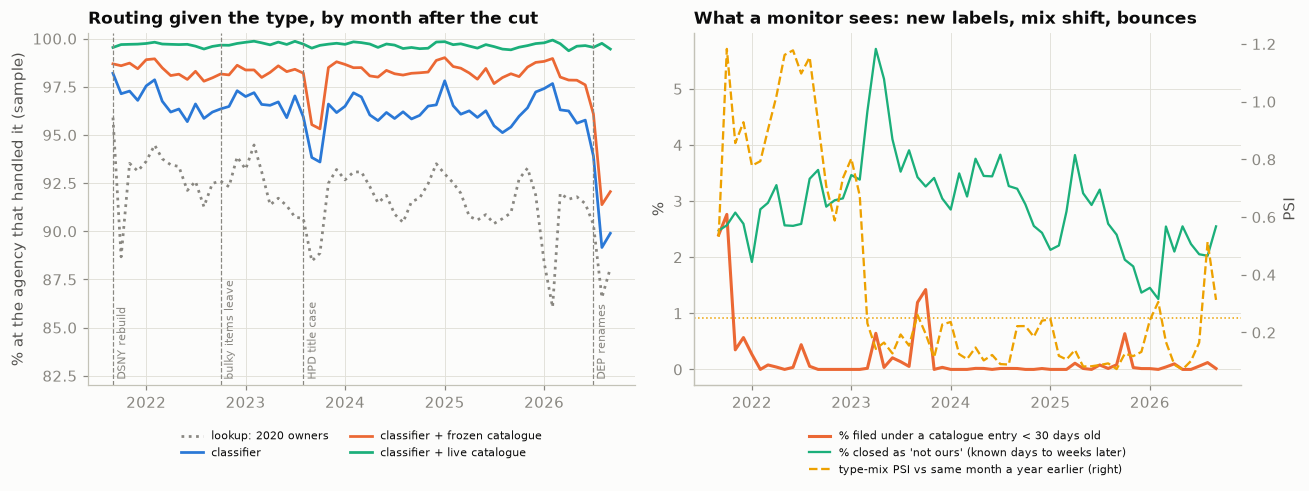

In [12]:
t0 = time.time()
months = rq.created_date.dt.to_period("M")
sm = rq[stream]
ROUTERS = {"lookup: 2020 owners": assign_agency(sm, sm.complaint_type, "train"), "classifier": r_cls_stream,
           "classifier + frozen catalogue": route_agency(sm, "frozen"), "classifier + live catalogue": route_agency(sm, "live")}
mon = pd.DataFrame({**{k: v == sm.agency.to_numpy() for k, v in ROUTERS.items()},
    "entry unknown to the 2020 catalogue": ~known_entry(sm, TRAIN_END),
    "filed under an entry < 30 days old": ((sm.created_date - sm.merge(kb[KEYS + ["first_seen"]], on=KEYS, how="left").first_seen.values)
                                           .dt.days < 30).values,
    "bounced": sm.bounced.to_numpy(),
}).groupby(months[stream].to_numpy()).mean()
def psi(ref: pd.Series, cur: pd.Series) -> float:
    r, c = ref.value_counts(normalize=True), cur.value_counts(normalize=True)
    keys = r.index.union(c.index)
    r_, c_ = r.reindex(keys).fillna(0).values + 1e-4, c.reindex(keys).fillna(0).values + 1e-4
    return float(np.sum((c_ - r_) * np.log(c_ / r_)))
mon["type-mix PSI vs a year earlier"] = [psi(rq[months == m - 12].complaint_type, rq[months == m].complaint_type) for m in mon.index]  # same season
rng_ = lambda c: f"{mon[c].min():.1%}–{mon[c].max():.1%} (mean {mon[c].mean():.1%})"
print(f"stream scored in {time.time() - t0:.0f}s · Sep 2021 – Sep 2026, agency accuracy by month: "
      + " · ".join(f"{k} {rng_(k)}" for k in ROUTERS) + f" · bounced {rng_('bounced')} · unknown entries {rng_('entry unknown to the 2020 catalogue')}")

EVENTS = {"2021-09": "DSNY rebuild", "2022-10": "bulky items leave", "2023-08": "HPD title case", "2026-07": "DEP renames"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]
tix = mon.index.to_timestamp()
for c, col, ls in zip(ROUTERS, [MUTED] + SERIES[:3], [":", "-", "-", "-"]):
    ax.plot(tix, mon[c] * 100, ls, lw=1.8, color=col, label=c)
for m_, lab in EVENTS.items():
    ax.axvline(pd.Timestamp(m_), color=MUTED, ls="--", lw=0.8)
    ax.text(pd.Timestamp(m_) + pd.Timedelta(days=12), 82.3, lab, rotation=90, fontsize=7, color=MUTED, va="bottom")
ax.set_ylim(82, 100.3); ax.set_ylabel("% at the agency that handled it (sample)")
ax.set_title("Routing given the type, by month after the cut")
ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
ax = axes[1]
ax.plot(tix, mon["filed under an entry < 30 days old"] * 100, lw=2, color=SERIES[1], label="% filed under a catalogue entry < 30 days old")
ax.plot(tix, mon["bounced"] * 100, lw=1.5, color=SERIES[2], label="% closed as 'not ours' (known days to weeks later)")
ax.set_ylabel("%"); ax2 = ax.twinx()
ax2.plot(tix, mon["type-mix PSI vs a year earlier"], lw=1.5, ls="--", color=SERIES[3], label="type-mix PSI vs same month a year earlier (right)")
ax2.axhline(0.25, color=SERIES[3], ls=":", lw=1); ax2.grid(False); ax2.set_ylabel("PSI")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.set_title("What a monitor sees: new labels, mix shift, bounces")
ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=1)
plt.tight_layout()
q = mon.loc[[pd.Period(m_) for m_ in ["2021-09", "2021-10", "2022-09", "2023-08", "2023-09", "2024-09", "2025-09", "2026-02",
                                         "2026-07", "2026-08", "2026-09"] if pd.Period(m_) in mon.index]]
q.style.format({c: "{:.1%}" for c in mon.columns if "PSI" not in c} | {"type-mix PSI vs a year earlier": "{:.2f}"})

In [13]:
# Real renames and additions, dated from the catalogue itself (full population, not the sample)
CHANGES = [("DCA", "Consumer Complaint", "DCWP", "Consumer Complaint", "agency renamed"),
           ("DSNY", "Dirty Conditions", "DSNY", "Dirty Condition", "type renamed, descriptors rewritten"),
           ("DSNY", "Missed Collection (All Materials)", "DSNY", "Missed Collection", "type merged"),
           ("DSNY", "Sanitation Condition", "DSNY", "Illegal Dumping", "type split (also Dead Animal, Obstruction …)"),
           ("DSNY", "Snow", "DSNY", "Snow or Ice", "type renamed"),
           ("NYPD", "Vending", "DSNY", "Vendor Enforcement", "work moved to another agency"),
           ("HPD", "HEAT/HOT WATER", "HPD", "Heat/Hot Water", "same label in title case, then back"),
           ("DOHMH", "Smoking", "DOHMH", "Smoking or Vaping", "type widened"),
           ("DEP", "Water System", "DEP", "Water Maintenance", "type renamed"),
           ("DEP", "Sewer", "DEP", "Sewer Maintenance", "type renamed"),
           ("DSNY", "Request Large Bulky Item Collection", None, None, "requests leave the 311 data")]
span = kb.groupby(["agency", "complaint_type"]).agg(first=("first_seen", "min"), last=("last_seen", "max"), n=("n", "sum"))
rows = []
for a0, t0_, a1, t1, what in CHANGES:
    o = span.loc[(a0, t0_)]
    nw = span.loc[(a1, t1)] if a1 else None
    rows.append({"old": f"{a0} · {t0_}", "last seen": f"{o['last']:%d %b %Y}", "new": f"{a1} · {t1}" if a1 else "—",
                 "first seen": f"{nw['first']:%d %b %Y}" if nw is not None else "—", "change": what,
                 "requests under the old label": f"{o['n']:,}"})
pd.DataFrame(rows)

,old,last seen,new,first seen,change,requests under the old label
0,DCA · Consumer Complaint,31 Jul 2020,DCWP · Consumer Complaint,01 Aug 2020,agency renamed,"27,905"
1,DSNY · Dirty Conditions,21 Sep 2021,DSNY · Dirty Condition,04 May 2021,"type renamed, descriptors rewritten","68,224"
2,DSNY · Missed Collection (All Materials),21 Sep 2021,DSNY · Missed Collection,17 Jan 2020,type merged,"82,824"
3,DSNY · Sanitation Condition,21 Sep 2021,DSNY · Illegal Dumping,21 Sep 2021,"type split (also Dead Animal, Obstruction …)","62,768"
4,DSNY · Snow,20 Mar 2021,DSNY · Snow or Ice,05 Oct 2021,type renamed,"9,415"
5,NYPD · Vending,14 Jan 2021,DSNY · Vendor Enforcement,31 Mar 2023,work moved to another agency,"4,353"
6,HPD · HEAT/HOT WATER,30 Sep 2026,HPD · Heat/Hot Water,10 Aug 2023,"same label in title case, then back","1,654,610"
7,DOHMH · Smoking,17 Nov 2024,DOHMH · Smoking or Vaping,03 Dec 2023,type widened,"15,718"
8,DEP · Water System,29 Jul 2026,DEP · Water Maintenance,13 Oct 2020,type renamed,"422,452"
9,DEP · Sewer,29 Jul 2026,DEP · Sewer Maintenance,09 Feb 2020,type renamed,"190,649"


**Frozen, the 2020 owner map falls from 99.1 % on test to 88.7 % in October 2021**, the first full month after DSNY's rebuild, and averages 91.8 % over five years (low 86.1 %): each month 3–17 % of requests use an entry it has never seen. **The classifier's words carry it further** (mean 96.1 %, but 89.2 % after DEP's 2026 renames), the frozen catalogue with the classifier reaches 98.0 %, and **the live catalogue holds 99.4–99.9 %** without retraining.

The signals catch different events. The **new-entry share** jumps with releases (2.4–2.8 % in September–October 2021, 1.2 % in September 2023) but misses DEP in 2026 (0.1 %), whose new names already existed. The **year-on-year PSI** catches DEP (0.51 in August 2026) but also snowy winters (0.31 in February 2026), and stays above 0.5 for more than a year after DSNY's rebuild. The **bounce rate** wanders between 1.3 % and 5.7 % and arrives late. The table dates eleven real changes, including a split and 632,148 bulky-item requests leaving 311 data after September 2022, a level shift the forecast must absorb. The plan needs all three signals and a same-day catalogue refresh on every release (C5).

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The card's plan, updated with what this notebook measured: starting values, not targets to copy.

| Spine | In this project — after this notebook |
|---|---|
| Package and container (S02–S03) | `src/civic_311/` (`fetch`, `catalogue` with as-of snapshots and the 911 list, `router`, `desk`, `forecast`); `POST /route` returns agency, source and desk flag; a daily forecast job. |
| Monitoring (S04) | Same day: share under catalogue entries under 30 days old (2.4–2.8 % at the 2021 release), unknown entries, desk load (205 a day on test, capacity 300). Monthly: year-on-year type-mix PSI (alert at 0.25). Later: bounce rate (1.3–5.7 %), desk precision, forecast MAPE. |
| CI/CD gate (S05) | Against the incumbent on the same fingerprinted months: router accuracy ≥ the 2020 lookup's (test 99.7 % against 99.1 %); forecast MAPE ≤ 0.9 × the seasonal naive's (2025: 7.6 % against 10.1 %); every routed agency exists in the live catalogue. |
| MLflow tracking and registry (S06) | Sample rule, fingerprints, catalogue snapshot (1,744 entries), desk threshold and costs, metrics per split; `champion`/`challenger`. |
| Offline / online training and serving | Online routing and desk flag; catalogue refreshed daily; bounce rates monthly as closures arrive; forecast refitted yearly. |
| Data and model drift | Releases (DSNY Sep 2021, HPD Aug–Oct 2023, DEP Jul 2026), DCA → DCWP, storms, heat seasons. 2020 owner map: 99.1 % on test, 88.7 % in Oct 2021. |
| Knowledge base and context (S07–S09) | Dated agency → type → descriptor catalogue, four competency questions. Ablation, test months: classifier 99.1 %, + frozen catalogue 99.1 %, + live 99.7 %; Sep 2021 – Sep 2026: 96.1 → 98.0 → 99.7 % on average. The desk's best score is a catalogue statistic (AUPRC 0.50, against 0.35 with context). |
| GenAI and context engineering (S10–S11) | Reply drafts from the routed entry and the agency's standard closures, never a location; 39 catalogue entries (0.9 % of requests) force a 911 handover before any generation. |
| Governance | Addresses never fetched; `unique_key` dropped; aggregates only; NYC Open Data terms (E4). |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap.** Tests that fail if a closure field reaches any model, a menu field reaches a before-the-type model, or a forecast input is under two days old; forward-in-time splits; small-agency figures; case-folded labels.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary desk capacity (100–600 a day), the costs and `DESK_FIX_RATE`; show how the threshold, the bounces caught and the saving move; write the ADR, naming who signs off the cost of a bounce.
- **C4 — Package, container and gate.** Package and containerise `POST /route`, the desk and the forecast job (Sessions 02–03); gate CI on the April–August 2021 holdout and the 2025 forecast year against the incumbents, refusing to run if a fingerprint changes (Session 05).
- **C5 — Register, document, monitor.** MLflow runs with fingerprints and catalogue snapshot; a `champion` alias; a model card (routing given the type, label delay, releases, costs); a monitoring plan with Section 7's signals and release-day refresh (Sessions 04, 06).

### Extension

- **E1 — Knowledge-base ablation.** Model the catalogue as an RDF graph (agency, type, descriptor, validity interval, owner, emergency flag), validate it with SHACL (one owner per type and date), and rerun the ablation from the graph on the test months and the stream (Sessions 07–09).
- **E2 — A crosswalk per release.** Derive DSNY's 2021 mapping from the catalogue, including the split of *Sanitation Condition*; measure how much of the frozen map's loss it recovers.
- **E3 — Surge days as an operations rule.** Using weather warnings as known the afternoon before (no new model or features), write a surge-day rule, count how many of 2025's 14 surge days it flags and at what false-alarm rate, and state the staffing action and who takes it.
- **E4 — Governance and transparency.** Your reading of the router's AI Act position (Annex III use, or a preparatory task under Article 6(3)?), the explanation a citizen is owed, and a small-cell rule for every published aggregate.

### Stretch

- **S1 — Citizen reply drafts with an LLM.** From `reply_context` alone, a versioned prompt with structured output; a 50-request golden set with 911 entries (handover, no draft) and a prompt injection; score consistency with the closures and cost per reply (Sessions 10–11).
- **S2 — Online and batch serving at the peak.** Serve `POST /route` at the peak hour of 24 Feb 2026 and run the daily forecast job as a scheduled batch with retries and a stale-input check; state latency and cost per thousand routes.
- **S3 — A free-text front door with an LLM.** Build a golden set of citizen-style descriptions (written by you, or from 311's service pages in the Kaggle web-content file), ask your LLM (see `docs/llm-access.md`) to pick the complaint type, and place its accuracy between 22.7 % (before the type) and 97.5 % (the descriptor); no model training.

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Repository in the Session 02 layout; fresh-clone test passes; `data/` not committed; no address, ZIP or coordinate ever requested
- [ ] `README.md` states the API source, window, 2 % sampling rule, extract fingerprints and the NYC Open Data terms
- [ ] Forward-in-time evaluation; traps removed; closure-field, menu-field and input-age tests in the suite
- [ ] Desk threshold from capacity and cost, with the ADR; forecast against the seasonal naive with intervals
- [ ] CI gates against the incumbents on fingerprinted months; registered models, model cards, monitoring plan
- [ ] Catalogue as a validated, versioned knowledge base, with the ablation
- [ ] One-page recommendation to the 311 operations lead: value, desk load, what routing cannot fix, the 911 rule
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `requests`, `scikit-learn`, `lightgbm`, `matplotlib`, `kagglehub` (pinned in `requirements.txt`). No LLM in the baseline. On a small laptop keep one suffix in `SAMPLE_SUFFIXES` (1 %).
- City of New York, *311 Service Requests from 2020 to Present* (`erm2-nwe9`, with its column descriptions) and *from 2010 to 2019* (`76ig-c548`), NYC Open Data; Kaggle `new-york-city/ny-311-service-requests` (December 2019). National Weather Service, New York, NY office: event summaries for Tropical Storm Isaias (4 Aug 2020) and the flash flooding of 29 Sep 2023.
- Huyen, C. (2022). *Designing Machine Learning Systems*, Ch. 4–5 (imbalance, leakage), Ch. 8 (distribution shift) · Hyndman, R. J., Athanasopoulos, G. (2021). *Forecasting: Principles and Practice*, 3rd ed., Ch. 5.
- Ke, G. et al. (2017). *LightGBM.* NeurIPS · Sculley, D. et al. (2015). *Hidden Technical Debt in Machine Learning Systems.* NeurIPS · Regulation (EU) 2024/1689 (AI Act).

In [14]:
print(f"pandas {pd.__version__} · numpy {np.__version__} · scikit-learn {sklearn.__version__} · lightgbm {lgb.__version__}")
print(f"notebook finished · total wall time {time.time() - T_START:.0f}s")

pandas 3.1.0 · numpy 2.5.4 · scikit-learn 1.9.1 · lightgbm 4.7.0
notebook finished · total wall time 210s
